# Construção de histórias para encantar o cliente
## Mais compras nem sempre significam mais faturamento
**Participante:** André Lucas Coelho de Jesus.

**Problema:** qual filial vende melhor e o que os gestores podem aprender com o valor de cada compra?
Vou analisar as vendas das três filiais, comparar os tickets e conferir se preço unitário e quantidade têm relação.

Base: Supermarket Sales, de Aung Pyae, indicada no enunciado. O link e a API do Kaggle retornaram 404 em 07/11/2026. Usei a cópia didática da CSU-AREC-330, que cita o Kaggle. Conferi as cinco primeiras faturas com a imagem da atividade. A cópia tinha cabeçalhos em snake_case; restaurei só os nomes das 17 colunas. Não foi possível confirmar identidade byte a byte com o original indisponível.

[Kaggle indicado](https://www.kaggle.com/datasets/aungpyaeap/supermarket-sales) · [Cópia didática e dicionário](https://csu-arec-330.github.io/materials/unit_00/inputs/supermarketdata_describe.html).
Os valores usam o símbolo `$` da base, sem conversão para reais. Cada linha representa uma compra, não um cliente único.

**No Colab:** Arquivo → Fazer upload de notebook. Depois execute as células. Se o CSV não estiver na pasta, a célula seguinte pede o upload de `supermarket_sales - Sheet1.csv`.

In [1]:
from pathlib import Path
import json
import io
import hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML, FileLink

ARQUIVO = 'supermarket_sales - Sheet1.csv'
candidatos = [Path('dados') / ARQUIVO, Path(ARQUIVO)]
arquivo = next((p for p in candidatos if p.is_file()), None)
if arquivo is None:
    try:
        from google.colab import files
    except ImportError as erro:
        raise FileNotFoundError(f'Coloque {ARQUIVO} na pasta dados ou junto do notebook.') from erro
    enviados = files.upload()
    if ARQUIVO not in enviados:
        raise ValueError(f'Envie o arquivo chamado {ARQUIVO}.')
    arquivo = Path(ARQUIVO)

sales = pd.read_csv(arquivo)
sales_original = sales.copy(deep=True)
saida = Path('resultados')
saida.mkdir(exist_ok=True)
print('SHA-256 do CSV:', hashlib.sha256(arquivo.read_bytes()).hexdigest())
print(f'{sales.shape[0]} linhas e {sales.shape[1]} colunas')
display(sales.head())
sales.info()

SHA-256 do CSV: 7c1c71affd1ed5839240de5a6edc8784672eefd12a07bd4dcf25099e40a2193e
1000 linhas e 17 colunas


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

## Limpeza antes da análise
Vou conferir nulos, duplicatas, tipos, datas, categorias e contas do arquivo. Não vou preencher valores ausentes com zero nem excluir compras caras só por serem altas.
As datas estão no formato mês/dia/ano. Uso esse formato explicitamente para não inverter janeiro e maio.
Duplicatas exatamente iguais podem ser removidas. Faturas repetidas com conteúdo diferente e registros inválidos interrompem a análise para revisão.

In [2]:
colunas = ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line',
           'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment',
           'cogs', 'gross margin percentage', 'gross income', 'Rating']
if set(sales.columns) != set(colunas):
    raise ValueError('O CSV não tem as 17 colunas esperadas. Confira a fonte.')

nulos_antes = int(sales.isna().sum().sum())
for coluna in sales.select_dtypes(include=['object', 'string']).columns:
    sales[coluna] = sales[coluna].str.strip().replace('', pd.NA)
duplicatas = int(sales.duplicated().sum())
sales = sales.drop_duplicates().copy()
if sales['Invoice ID'].duplicated().any():
    raise ValueError('Há faturas repetidas com dados diferentes; revisar antes de agregar.')

numericas = ['Unit price', 'Quantity', 'Tax 5%', 'Total', 'cogs',
             'gross margin percentage', 'gross income', 'Rating']
for coluna in numericas:
    sales[coluna] = pd.to_numeric(sales[coluna], errors='coerce')
sales['Date'] = pd.to_datetime(sales['Date'], format='%m/%d/%Y', errors='coerce')
sales['Time'] = pd.to_datetime(sales['Time'], format='%H:%M', errors='coerce')

regras = pd.DataFrame(index=sales.index)
regras['campo_ausente_ou_conversao_invalida'] = sales.isna().any(axis=1)
regras['numero_nao_finito'] = ~np.isfinite(sales[numericas].to_numpy()).all(axis=1)
regras['preco_invalido'] = sales['Unit price'].le(0)
regras['quantidade_invalida'] = sales['Quantity'].le(0) | sales['Quantity'].mod(1).ne(0)
regras['valor_negativo'] = sales[['Tax 5%', 'Total', 'cogs', 'gross income']].lt(0).any(axis=1)
regras['avaliacao_fora_de_1_a_10'] = ~sales['Rating'].between(1, 10)
dominios = {'Branch': ['A', 'B', 'C'], 'City': ['Yangon', 'Mandalay', 'Naypyitaw'],
            'Gender': ['Female', 'Male'], 'Customer type': ['Member', 'Normal'],
            'Payment': ['Cash', 'Credit card', 'Ewallet'],
            'Product line': ['Electronic accessories', 'Fashion accessories', 'Food and beverages',
                             'Health and beauty', 'Home and lifestyle', 'Sports and travel']}
for coluna, valores in dominios.items():
    regras['categoria_invalida_' + coluna] = ~sales[coluna].isin(valores)
mapa_filiais = {'A': 'Yangon', 'B': 'Mandalay', 'C': 'Naypyitaw'}
regras['filial_cidade_incoerente'] = sales['City'].ne(sales['Branch'].map(mapa_filiais))
regras['cogs_incoerente'] = ~np.isclose(sales['cogs'], sales['Unit price'] * sales['Quantity'], rtol=0, atol=1e-6)
regras['imposto_incoerente'] = ~np.isclose(sales['Tax 5%'], sales['cogs'] * .05, rtol=0, atol=1e-6)
regras['total_incoerente'] = ~np.isclose(sales['Total'], sales['cogs'] + sales['Tax 5%'], rtol=0, atol=1e-6)
regras['margem_incoerente'] = ~np.isclose(sales['gross margin percentage'], 100 * sales['gross income'] / sales['Total'], rtol=0, atol=1e-7)
invalidos = regras.any(axis=1)
auditoria = regras.sum().astype(int).rename('registros').to_frame()
display(auditoria)
auditoria.to_csv(saida / 'auditoria_regras.csv', encoding='utf-8-sig')
if invalidos.any():
    sales.loc[invalidos].to_csv(saida / 'registros_para_revisao.csv', index=False)
    raise ValueError('Há registros inválidos. Consulte registros_para_revisao.csv antes de continuar.')

sales['Quantity'] = sales['Quantity'].astype(int)
sales['Mes'] = sales['Date'].dt.strftime('%Y-%m')
sales['Hora'] = sales['Time'].dt.hour
qualidade = {'linhas_originais': len(sales_original), 'colunas_originais': len(sales_original.columns),
             'nulos_originais': nulos_antes, 'duplicatas_removidas': duplicatas,
             'linhas_invalidas': int(invalidos.sum()), 'linhas_finais': len(sales),
             'nulos_apos_limpeza': int(sales.isna().sum().sum())}
display(pd.Series(qualidade, name='Quantidade').to_frame())
(saida / 'qualidade.json').write_text(json.dumps(qualidade, indent=2), encoding='utf-8')
sales_exportacao = sales.copy()
sales_exportacao['Date'] = sales_exportacao['Date'].dt.strftime('%Y-%m-%d')
sales_exportacao['Time'] = sales_exportacao['Time'].dt.strftime('%H:%M')
sales_exportacao.to_csv(saida / 'sales_limpo.csv', index=False, encoding='utf-8-sig')

,registros
campo_ausente_ou_conversao_invalida,0
numero_nao_finito,0
preco_invalido,0
quantidade_invalida,0
valor_negativo,0
avaliacao_fora_de_1_a_10,0
categoria_invalida_Branch,0
categoria_invalida_City,0
categoria_invalida_Gender,0
categoria_invalida_Customer type,0


,Quantidade
linhas_originais,1000
colunas_originais,17
nulos_originais,0
duplicatas_removidas,0
linhas_invalidas,0
linhas_finais,1000
nulos_apos_limpeza,0


## O que a base permite concluir
O arquivo já veio sem nulos ou duplicatas. A limpeza não precisa inventar alterações: o trabalho aqui foi validar os dados e converter os tipos.
`gross income` coincide com `Tax 5%` em todas as linhas. Por isso não vou chamar esse campo de lucro operacional ou líquido. Faltam despesas e uma definição contábil confiável para isso.
Também não dá para usar `Invoice ID` como identificação de cliente ou medir recompra individual.
Cada fatura informa uma categoria; não dá para reconstruir uma cesta com vários produtos ou medir compra conjunta entre categorias.
Para um modelo futuro, é preciso definir o alvo antes: se a meta for prever Total, usar imposto, cogs e gross income calculados na própria compra causaria vazamento de informação. A divisão entre treino e teste também precisa respeitar o tempo.

In [3]:
por_cidade = sales.groupby('City').agg(Compras=('Total', 'size'),
    Faturamento=('Total', 'sum'), Ticket_medio=('Total', 'mean'), Avaliacao=('Rating', 'mean'))
por_cidade['Participacao_pct'] = por_cidade['Faturamento'] / sales['Total'].sum() * 100
por_genero = sales.groupby('Gender').agg(Compras=('Total', 'size'), Faturamento=('Total', 'sum'), Ticket_medio=('Total', 'mean'))
por_categoria = sales.groupby('Product line').agg(Compras=('Total', 'size'), Faturamento=('Total', 'sum')).sort_values('Faturamento', ascending=False)
por_mes = sales.groupby('Mes').agg(Compras=('Total', 'size'), Faturamento=('Total', 'sum'), Dias_observados=('Date', 'nunique'))
por_mes['Media_por_dia_observado'] = por_mes['Faturamento'] / por_mes['Dias_observados']
correlacao = float(sales['Unit price'].corr(sales['Quantity']))
resumo = {'compras': len(sales), 'unidades': int(sales['Quantity'].sum()),
          'faturamento': float(sales['Total'].sum()), 'ticket_medio': float(sales['Total'].mean()),
          'mediana_compra': float(sales['Total'].median()), 'avaliacao': float(sales['Rating'].mean()),
          'inicio': sales['Date'].min().strftime('%d/%m/%Y'), 'fim': sales['Date'].max().strftime('%d/%m/%Y'),
          'correlacao_preco_quantidade': correlacao,
          'vantagem_ticket_naypyitaw_yangon_pct': float((por_cidade.loc['Naypyitaw', 'Ticket_medio'] / por_cidade.loc['Yangon', 'Ticket_medio'] - 1) * 100),
          'gross_income_igual_imposto': bool(np.allclose(sales['gross income'], sales['Tax 5%']))}
display(pd.Series(resumo, name='Resultado').to_frame())
for nome, tabela in [('cidades', por_cidade), ('generos', por_genero), ('categorias', por_categoria), ('meses', por_mes)]:
    print('\n' + nome.upper())
    display(tabela.round(2))
    tabela.to_csv(saida / (nome + '.csv'), encoding='utf-8-sig')
(saida / 'resumo.json').write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding='utf-8')

,Resultado
compras,1000
unidades,5510
faturamento,322966.749
ticket_medio,322.966749
mediana_compra,253.848
avaliacao,6.9727
inicio,01/01/2019
fim,30/03/2019
correlacao_preco_quantidade,0.010778
vantagem_ticket_naypyitaw_yangon_pct,7.922319



CIDADES


,Compras,Faturamento,Ticket_medio,Avaliacao,Participacao_pct
City,,,,,
Mandalay,332,106197.67,319.87,6.82,32.88
Naypyitaw,328,110568.71,337.10,7.07,34.24
Yangon,340,106200.37,312.35,7.03,32.88



GENEROS


,Compras,Faturamento,Ticket_medio
Gender,,,
Female,501,167882.92,335.10
Male,499,155083.82,310.79



CATEGORIAS


,Compras,Faturamento
Product line,,
Food and beverages,174,56144.84
Sports and travel,166,55122.83
Electronic accessories,170,54337.53
Fashion accessories,178,54305.90
Home and lifestyle,160,53861.91
Health and beauty,152,49193.74



MESES


,Compras,Faturamento,Dias_observados,Media_por_dia_observado
Mes,,,,
2019-01,352,116291.87,31,3751.35
2019-02,303,97219.37,28,3472.12
2019-03,345,109455.51,30,3648.52


354

## A história dos dados
Yangon teve mais compras: 340. Naypyitaw teve 328 e, mesmo assim, liderou o faturamento com $ 110.568,71. O ticket médio de Naypyitaw foi $ 337,10, contra $ 312,35 em Yangon, uma diferença de 7,92%.
Isso sugere investigar a composição das compras e testar ofertas que aumentem o valor da cesta. A comparação é descritiva: ela não prova que uma ação específica causou o resultado.

As compras ficaram quase divididas entre os gêneros registrados: 501 e 499. São compras, não pessoas diferentes.
Alimentos e bebidas liderou o faturamento com $ 56.144,84, mas as categorias têm valores próximos. A quantidade de compras por categoria também importa.
A correlação entre preço unitário e quantidade foi aproximadamente 0,011: nesta amostra, quase não há relação linear. Isso não prova que preço não afete a demanda.

Fevereiro teve menor faturamento total, mas também teve menos dias. A tabela mensal mostra a média por dia observado. Março vai só até o dia 30; três meses não sustentam uma conclusão de sazonalidade anual.

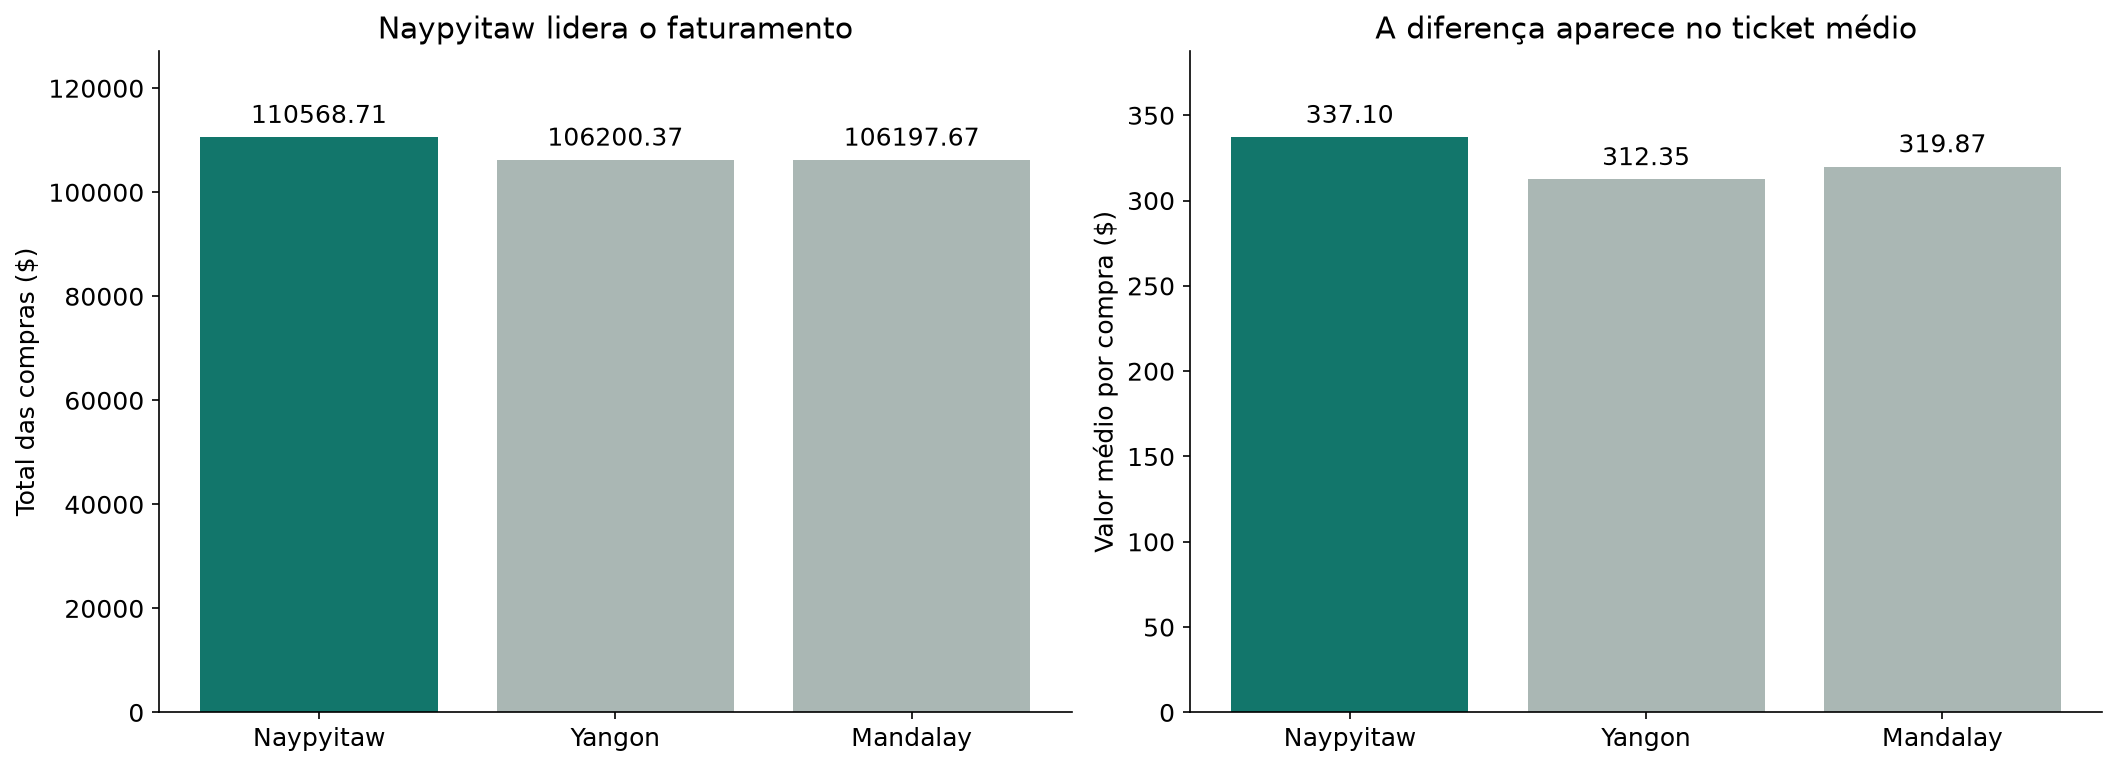

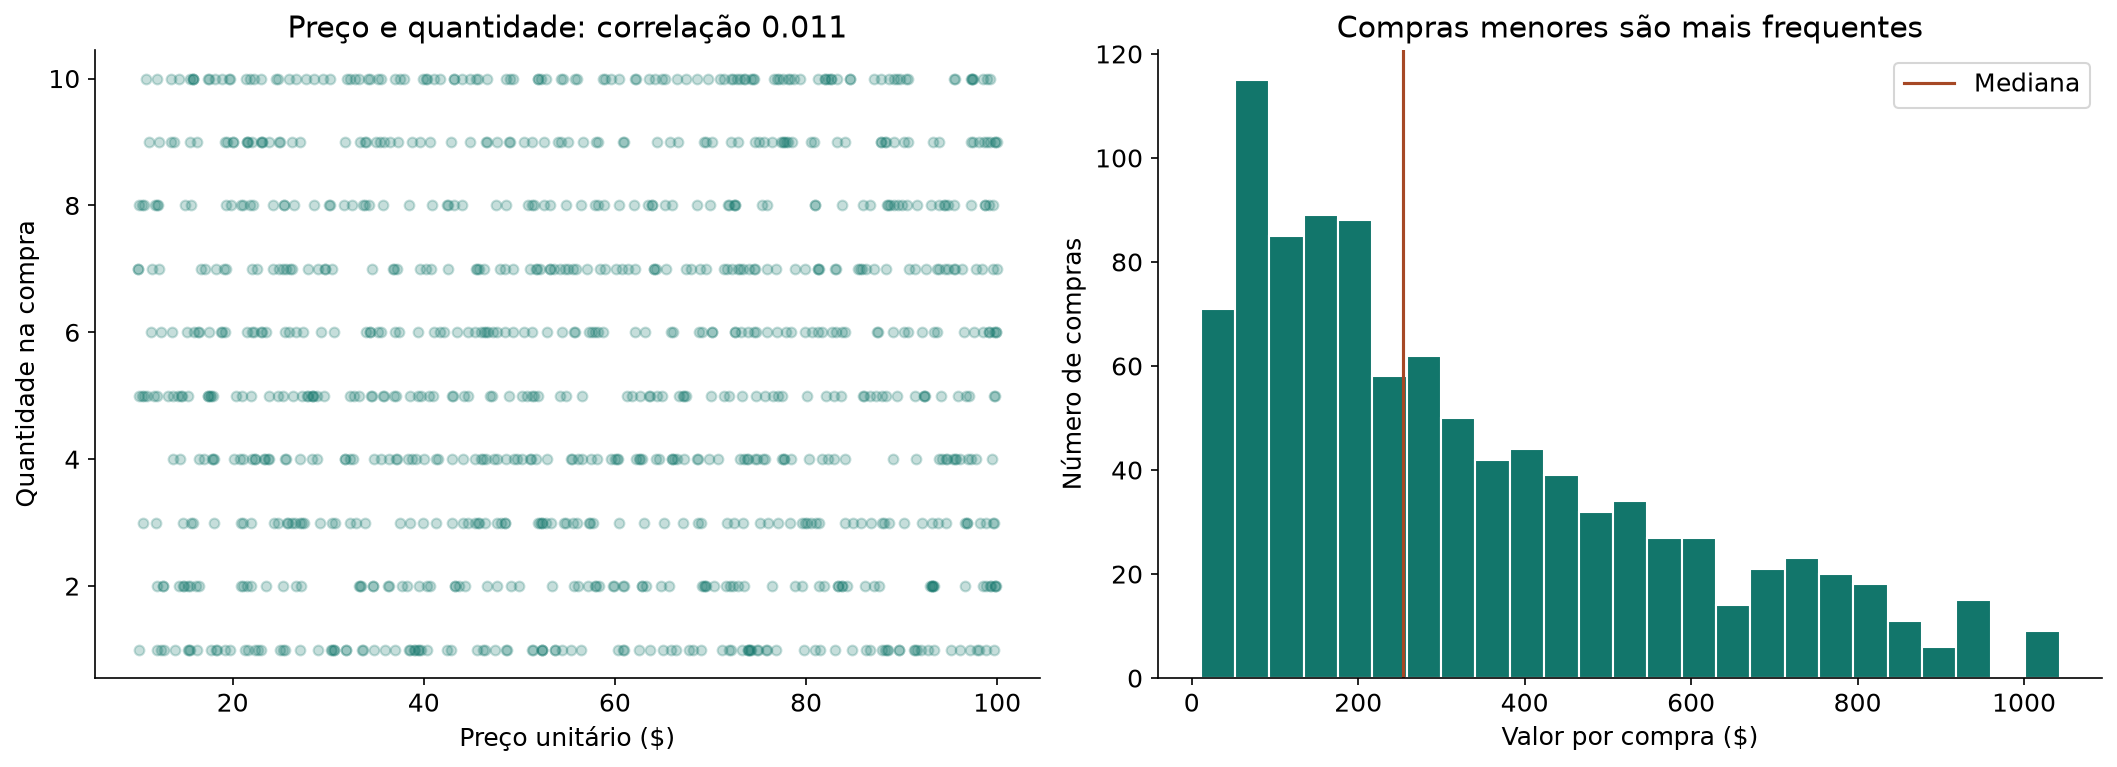

In [4]:
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
cores = ['#12766b', '#aab7b4', '#aab7b4']
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
ordem = por_cidade.sort_values('Faturamento', ascending=False)
eixos[0].bar(ordem.index, ordem['Faturamento'], color=cores)
eixos[0].set(title='Naypyitaw lidera o faturamento', ylabel='Total das compras ($)')
eixos[1].bar(ordem.index, ordem['Ticket_medio'], color=cores)
eixos[1].set(title='A diferença aparece no ticket médio', ylabel='Valor médio por compra ($)')
for eixo in eixos:
    eixo.bar_label(eixo.containers[0], fmt='%.2f', padding=4)
    eixo.margins(y=.15)
fig.savefig(saida / 'cidades_ticket.png', dpi=150, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(saida / 'cidades_ticket.png')))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
eixos[0].scatter(sales['Unit price'], sales['Quantity'], alpha=.24, color='#12766b', s=22)
eixos[0].set(title=f'Preço e quantidade: correlação {correlacao:.3f}', xlabel='Preço unitário ($)', ylabel='Quantidade na compra')
eixos[1].hist(sales['Total'], bins=25, color='#12766b', edgecolor='white')
eixos[1].axvline(sales['Total'].median(), color='#a64825', label='Mediana')
eixos[1].set(title='Compras menores são mais frequentes', xlabel='Valor por compra ($)', ylabel='Número de compras')
eixos[1].legend()
fig.savefig(saida / 'preco_cesta.png', dpi=150, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(saida / 'preco_cesta.png')))

## Dashboard com filtros
A próxima célula gera um painel HTML que funciona sem internet. Os filtros de cidade e mês mudam os indicadores e os seis gráficos. Os números de cada recorte são calculados com Pandas.
No Colab, execute a célula e abra o arquivo `dashboard.html` pela aba Arquivos. Também é possível baixar e abrir no navegador.

In [5]:
"""Código incorporado ao notebook; usa o dataframe sales já validado."""
import plotly.graph_objects as go
from plotly.offline import get_plotlyjs

categorias_pt = {'Food and beverages': 'Alimentos e bebidas', 'Sports and travel': 'Esportes e viagens',
    'Electronic accessories': 'Acessórios eletrônicos', 'Fashion accessories': 'Acessórios de moda',
    'Home and lifestyle': 'Casa e estilo de vida', 'Health and beauty': 'Saúde e beleza'}
base_layout = dict(template='plotly_white', font=dict(family='Arial', size=13, color='#263530'),
    margin=dict(l=55, r=20, t=22, b=55), paper_bgcolor='white', plot_bgcolor='white',
    height=310, showlegend=False, colorway=['#12766b'])

def figura(trace, x=None, y=None):
    fig = go.Figure(trace)
    fig.update_layout(**base_layout)
    fig.update_xaxes(title_text=x, gridcolor='#edf0ee', automargin=True)
    fig.update_yaxes(title_text=y, gridcolor='#edf0ee', automargin=True)
    return json.loads(fig.to_json())

paineis = {}
for cidade in ['Todas', *sorted(sales['City'].unique())]:
    for mes in ['Todos', *sorted(sales['Mes'].unique())]:
        recorte = sales.copy()
        if cidade != 'Todas':
            recorte = recorte[recorte['City'].eq(cidade)]
        if mes != 'Todos':
            recorte = recorte[recorte['Mes'].eq(mes)]
        cidades = recorte.groupby('City')['Total'].sum().sort_values(ascending=False)
        categorias = recorte.groupby('Product line')['Total'].sum().sort_values()
        generos = recorte['Gender'].value_counts().reindex(['Female', 'Male'], fill_value=0)
        dias = recorte.groupby('Date')['Total'].sum().sort_index()
        r = recorte['Unit price'].corr(recorte['Quantity'])
        graficos = {
            'cidades': figura(go.Bar(x=cidades.index.tolist(), y=cidades.tolist(), marker_color='#12766b',
                hovertemplate='%{x}<br>$ %{y:,.2f}<extra></extra>'), y='Faturamento ($)'),
            'categorias': figura(go.Bar(x=categorias.tolist(), y=[categorias_pt[c] for c in categorias.index],
                orientation='h', marker_color='#12766b', hovertemplate='%{y}<br>$ %{x:,.2f}<extra></extra>'), x='Faturamento ($)'),
            'generos': figura(go.Bar(x=['Feminino', 'Masculino'], y=generos.tolist(), marker_color=['#12766b', '#8eaaa4'],
                text=generos.tolist(), textposition='auto'), y='Número de compras'),
            'diario': figura(go.Scatter(x=dias.index.strftime('%Y-%m-%d').tolist(), y=dias.tolist(),
                mode='lines', line=dict(color='#12766b', width=2), hovertemplate='%{x}<br>$ %{y:,.2f}<extra></extra>'), x='Data', y='Faturamento ($)'),
            'dispersao': figura(go.Scatter(x=recorte['Unit price'].tolist(), y=recorte['Quantity'].tolist(),
                mode='markers', marker=dict(color='#12766b', opacity=.28, size=6),
                hovertemplate='Preço: $ %{x:.2f}<br>Quantidade: %{y}<extra></extra>'), x='Preço unitário ($)', y='Quantidade por compra'),
            'cestas': figura(go.Histogram(x=recorte['Total'].tolist(), nbinsx=20, marker_color='#12766b'),
                x='Valor por compra ($)', y='Número de compras')}
        graficos['categorias']['layout']['margin']['l'] = 165
        paineis[cidade + '|' + mes] = {'compras': len(recorte), 'faturamento': float(recorte['Total'].sum()),
            'ticket': float(recorte['Total'].mean()), 'avaliacao': float(recorte['Rating'].mean()),
            'r': float(r) if pd.notna(r) else None, 'graficos': graficos}

payload = json.dumps(paineis, ensure_ascii=False, allow_nan=False)
template = '''<!doctype html><html lang="pt-BR"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Vendas do supermercado</title><style>
*{box-sizing:border-box}body{margin:0;background:#f2f5f3;color:#203a30;font:15px Arial,sans-serif}header{background:#153e34;color:white;padding:28px 36px}h1{margin:0 0 9px;font-size:30px}header p{margin:5px 0;color:#d8e9e1}.wrap{max-width:1600px;margin:auto;padding:22px 30px}.controls{display:flex;gap:20px;align-items:end;flex-wrap:wrap;margin-bottom:18px}label{display:grid;gap:6px;font-weight:bold}select,button{font:inherit;padding:9px 14px;border:1px solid #b0c3b8;border-radius:5px;background:white;color:#203a30}button{cursor:pointer}.kpis{display:grid;grid-template-columns:repeat(4,1fr);gap:14px;margin-bottom:18px}.kpi{background:white;border-top:4px solid #12766b;padding:17px}.kpi span{display:block;font-size:13px;color:#52675c}.kpi strong{display:block;font-size:27px;margin-top:9px}.grid{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:16px}.chart{background:white;padding:15px 10px 4px;min-width:0}.chart h2{font-size:16px;margin:0 10px 5px}.chart p{margin:2px 10px;color:#52675c;font-size:12px}.plot{width:100%;height:310px}.nota{line-height:1.5;font-size:13px;color:#4b6055}footer{margin-top:22px;border-top:1px solid #c4d3cb;padding-top:15px}.story{background:#dfece5;padding:14px 18px;border-left:4px solid #12766b;margin-bottom:20px;line-height:1.55}@media(max-width:1100px){.grid{grid-template-columns:repeat(2,minmax(0,1fr))}}@media(max-width:650px){.kpis,.grid{grid-template-columns:1fr}.wrap{padding:18px}header{padding:22px}h1{font-size:25px}}
</style><script>__PLOTLY__</script></head><body>
<header><h1>Mais compras nem sempre significam mais faturamento</h1><p>Construção de histórias para encantar o cliente</p><p>André Lucas Coelho de Jesus · Fundamentos em Big Data</p></header>
<main class="wrap"><div class="story"><strong>Ponto de partida:</strong> Naypyitaw faturou $ 110.568,71 com 328 compras. Yangon teve 340 compras e faturou $ 106.200,37. O ticket médio foi 7,92% maior em Naypyitaw.</div>
<div class="controls"><label>Cidade<select id="cidade"><option>Todas</option><option>Mandalay</option><option>Naypyitaw</option><option>Yangon</option></select></label><label>Período<select id="mes"><option value="Todos">Todo o período</option><option value="2019-01">Janeiro de 2019</option><option value="2019-02">Fevereiro de 2019</option><option value="2019-03">Março de 2019 (até dia 30)</option></select></label><button id="limpar">Limpar filtros</button><span id="recorte" aria-live="polite"></span></div>
<div class="kpis"><div class="kpi"><span>Compras</span><strong id="compras"></strong></div><div class="kpi"><span>Faturamento com imposto ($)</span><strong id="faturamento"></strong></div><div class="kpi"><span>Ticket médio ($)</span><strong id="ticket"></strong></div><div class="kpi"><span>Avaliação média (1 a 10)</span><strong id="avaliacao"></strong></div></div>
<div class="grid"><section class="chart"><h2>Faturamento por cidade</h2><div id="cidades" class="plot"></div></section><section class="chart"><h2>Categorias por faturamento</h2><div id="categorias" class="plot"></div></section><section class="chart"><h2>Compras por gênero registrado</h2><p>Contagem de compras; não representa clientes únicos.</p><div id="generos" class="plot"></div></section><section class="chart"><h2>Vendas ao longo do período</h2><div id="diario" class="plot"></div></section><section class="chart"><h2>Preço unitário e quantidade</h2><p id="correlacao"></p><div id="dispersao" class="plot"></div></section><section class="chart"><h2>Distribuição do valor das compras</h2><div id="cestas" class="plot"></div></section></div>
<footer class="nota"><strong>Leitura:</strong> faturamento é a soma de Total, incluindo o imposto de 5%. Ticket é faturamento dividido pelo número de compras. $ é a unidade indicada na base, sem conversão para reais.<br><strong>Qualidade:</strong> 1.000 registros validados; nenhum nulo, duplicata ou erro nas regras de consistência. Datas de 01/01/2019 a 30/03/2019. Os indicadores e todos os gráficos seguem os filtros; o texto inicial compara o período completo.<br><strong>Limites:</strong> gross income repete Tax 5% e não foi tratado como lucro. Sem identificação de clientes ou custos operacionais, não dá para medir recompra ou lucro líquido. Correlação não demonstra causalidade.<br><strong>Fonte:</strong> Aung Pyae / Supermarket Sales (Kaggle). Cópia didática CSU-AREC-330; cabeçalhos restaurados. Consulte o notebook para a origem dos dados e os cuidados da análise.</footer></main>
<script>const PAINEIS=__DADOS__;const cidade=document.getElementById('cidade'),mes=document.getElementById('mes');const numero=(v,d=0)=>v.toLocaleString('pt-BR',{minimumFractionDigits:d,maximumFractionDigits:d});let primeiro=true;async function atualizar(){const p=PAINEIS[cidade.value+'|'+mes.value];for(const id of ['compras','faturamento','ticket','avaliacao'])document.getElementById(id).textContent=numero(p[id],id==='compras'?0:2);document.getElementById('recorte').textContent=cidade.value+' · '+mes.options[mes.selectedIndex].text;document.getElementById('correlacao').textContent='Correlação linear (Pearson): '+numero(p.r,3);await Promise.all(Object.entries(p.graficos).map(([id,g])=>Plotly.react(id,g.data,g.layout,{responsive:true,displaylogo:false})));window.dashboardPronto=true;}cidade.addEventListener('change',atualizar);mes.addEventListener('change',atualizar);document.getElementById('limpar').addEventListener('click',()=>{cidade.value='Todas';mes.value='Todos';atualizar()});atualizar();</script></body></html>'''
html = template.replace('__PLOTLY__', get_plotlyjs()).replace('__DADOS__', payload)
Path('dashboard.html').write_text(html, encoding='utf-8')
(saida / 'paineis.json').write_text(payload, encoding='utf-8')
print('Dashboard gerado: dashboard.html')
display(FileLink('dashboard.html'))

Dashboard gerado: dashboard.html


C:\Projetos\SENAI\Fundamentos em Big Data\Parada Obrigatória 2\dashboard.html

## Conclusão para os gestores
Eu começaria comparando as categorias e os tamanhos das compras entre Naypyitaw e Yangon. Depois testaria uma oferta de produtos complementares e acompanharia ticket, faturamento, quantidade e avaliação.
Não recomendaria aumentar preços só com essa análise. A correlação não mostra um efeito causal e faltam custos, estoques e histórico mais longo.
Também manteria atenção em alimentos e bebidas, sem abandonar as outras categorias, porque a vantagem no faturamento não é grande.
O próximo passo é medir o resultado do teste antes de expandir para toda a rede.